# U1 — disponibilidad reportada: histórico ampliado

**Pregunta:** ¿con qué precisión podemos predecir los conteos reportados por tipo de bicicletas convencionales y eléctricas por estación a 5, 10 y 15 minutos?

Este notebook ejecuta **el mismo orquestador del punto de entrada**, desde un kernel limpio: lectura → calidad/Silver → preparación/Gold → entrenamiento/comparación → selección → prueba → guardado/recarga. No descarga ni necesita credenciales. Los 290 archivos y resultados de un día se conservan como prueba preliminar en `notebooks/archivo/` y `data/archivo_preliminar/`.

Inicio recomendado desde la raíz del repositorio:

```bash
.venv/bin/python pyspark/jupyter/UNIDAD1/Dim-Disponibilidad/ejecutar_u1.py --notebook --nueva
```

El lanzador comprueba Docker y monta el contexto público. `Run All` también funciona usando ese contexto ya preparado, sin editar rutas. Las capturas permanecen intactas bajo el montaje `./jupyter:/opt`.


## Arquitectura y alcance

Se elige **Lambda**: una ruta batch histórica reproducible sirve para auditar y entrenar, mientras una futura ruta de eventos servirá para inferencia en vivo. La disponibilidad puede cambiar sin un viaje —devoluciones, redistribución, mantenimiento—; no equivale a demanda de viajes. Kappa exigiría conservar/reproducir todo como un flujo duradero; el histórico actual es un archivo de snapshots en Storage, no un log Kafka reproducible. Lambda aprovecha esa fuente sin suponer infraestructura de streaming existente.

```text
U1 implementada: GBFS → capturador externo → Storage → descarga incremental → raw
                → lectura PySpark → Silver → Gold → comparación → artefactos
U2 futura:      GBFS → productor → Kafka → Structured Streaming → inferencia
                → PostgreSQL → Grafana (NO IMPLEMENTADA para esta dimensión)
```

No se afirma que el capturador externo esté implementado en esta carpeta. Las dos rutas futuras requerirán conservar el mismo contrato de variables para evitar diferencias batch/streaming.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, os, sys
from IPython.display import Markdown, SVG, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/flujo_u1.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from ejecutar_u1 import crear_ejecucion
from src.flujo_u1 import ejecutar
from src.ejecucion import comprobar_artefactos
if os.environ.get('U1_RUN_DIR'):
    RUN = Path(os.environ['U1_RUN_DIR'])
else:
    context_file=ROOT/'data/contexto_notebook.json'
    if not context_file.exists():
        raise RuntimeError('Primero ejecutar el punto de entrada con --notebook para verificar el Docker existente')
    RUN=crear_ejecucion(json.loads(context_file.read_text()))
config=json.loads((RUN/'configuracion.json').read_text())
print('Ejecución:',RUN.name,'; configuración UTC:',config)
print('Raw:',ROOT/'data/raw','; sin conexión a Supabase')


Ejecución: 20261117T171917344468Z ; configuración UTC: {'desde': '2026-11-09', 'hasta': '2026-11-16', 'inicio_modelado_utc': '2026-11-10 00:00:00', 'corte_validacion_utc': '2026-11-14 00:00:00', 'corte_prueba_utc': '2026-11-15 00:00:00', 'fin_exclusivo_utc': '2026-11-17 00:00:00', 'max_edad_s': 450, 'hueco_max_s': 450, 'tolerancia_s': 30, 'cores': 2, 'driver_memory': '4g', 'shuffle_partitions': 32}
Raw: /opt/UNIDAD1/Dim-Disponibilidad/data/raw ; sin conexión a Supabase


In [2]:
# Única implementación del flujo: se reutiliza desde CLI y notebook.
manifest=ejecutar(RUN,nueva=os.environ.get('U1_FORZAR_NUEVA','0')=='1')
assert manifest['estado']=='completada'
SOURCE=RUN if manifest['modo']=='nueva' else RUN.parent/manifest['ejecucion_fuente']
meta=json.loads((SOURCE/'manifiesto.json').read_text())
comprobar_artefactos(SOURCE,meta['artefactos'])
print('Flujo completo:',manifest['estado'],manifest['modo'],'; duración (s):',manifest['duracion_s'])
print('Linaje:',meta['linaje'])
print('Versiones:',meta['versiones'])


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 17:19:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Etapa: inventario_local


Etapa: lectura


Etapa: calidad_silver


26/11/17 17:19:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


... (62 outputs left out)

Etapa: verificacion_final


Etapa: raw_intacto


U1 completada: nueva 20261117T171917344468Z


Flujo completo: completada nueva ; duración (s): 5433.202770622003
Linaje: {'raw': 'data/raw', 'silver': '/opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T171917344468Z/silver', 'gold': '/opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T171917344468Z/gold', 'modelos': '/opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T171917344468Z/modelos', 'silver_ejecucion': '20261117T171917344468Z', 'gold_ejecucion': '20261117T171917344468Z', 'modelos_ejecucion': '20261117T171917344468Z'}
Versiones: {'integracion': 'u1-integrado-v2-historico', 'silver': 'silver-v2-tipos-gbfs', 'gold': 'gold-v3-emparejamiento-estrecho', 'modelado': 'modelado-v2-regularizacion-interpretacion', 'spark': '4.2.0', 'python': '3.10.22', 'java': '21.0.13', 'docker_imagen_id': 'sha256:776b7bfde33a05e845392e5bf9cc88be81167c0b328f40142de729def297120d'}


In [3]:
# Evidencia acotada de esquema y ejemplos; el flujo completo ya terminó.
from pyspark.sql import SparkSession, functions as F
from src.lectura import esquema, leer_fuente
sp=(SparkSession.builder.master(f"local[{config['cores']}]").appName('U1-esquemas-y-ejemplos')
    .config('spark.sql.session.timeZone','UTC').config('spark.ui.enabled','false')
    .config('spark.ui.showConsoleProgress','false').getOrCreate())
sp.sparkContext.setLogLevel('ERROR')
for source in ('station_status','station_information','vehicle_types'):
    print('Esquema explícito de entrada:',source,esquema(source).simpleString())
_,catalog=leer_fuente(sp,ROOT/'data/raw','vehicle_types')
catalog.select('vehicle_type_id','form_factor','propulsion_type').distinct().show(truncate=False)
accepted=sp.read.parquet(str(SOURCE/'silver/aceptados'))
print('Esquema real Silver y ejemplos trazables:')
accepted.printSchema()
accepted.select('station_id','captura_utc','last_updated','last_reported','vehicle_types_available',
    'num_bikes_available','num_ebikes_available','q_discrepancia_total','archivo_origen').show(3,truncate=False)
sp.read.parquet(str(SOURCE/'silver/excluidos')).select('station_id','captura_utc','tipo_registro',
    'num_bikes_available','vehicle_types_available','motivos_exclusion').show(3,truncate=False)
gold_view=sp.read.parquet(str(SOURCE/'gold/aceptados'))
print('Esquema real Gold y objetivos observados:')
gold_view.printSchema()
gold_view.select('station_id','captura_utc','f_captura_utc','horizonte_min','horizonte_efectivo_s',
    'y_convencionales','y_electricas','q_discrepancia_total','f_q_discrepancia_total').show(3,truncate=False)
sp.stop()


Esquema explícito de entrada: station_status struct<data:struct<stations:array<struct<station_id:string,num_bikes_available:bigint,num_ebikes_available:bigint,num_bikes_disabled:bigint,num_docks_available:bigint,num_docks_disabled:bigint,is_installed:bigint,is_renting:bigint,is_returning:bigint,last_reported:bigint,num_scooters_available:bigint,num_scooters_unavailable:bigint,vehicle_types_available:array<struct<vehicle_type_id:string,count:bigint>>>>>,last_updated:bigint,ttl:bigint,version:string,_corrupt_record:string>
Esquema explícito de entrada: station_information struct<data:struct<stations:array<struct<station_id:string,name:string,short_name:string,lon:double,lat:double,region_id:string,capacity:bigint,rental_uris:map<string,string>,is_charging:boolean>>>,last_updated:bigint,ttl:bigint,version:string,_corrupt_record:string>
Esquema explícito de entrada: vehicle_types struct<data:struct<vehicle_types:array<struct<vehicle_type_id:string,form_factor:string,propulsion_type:string,

+---------------+-----------+---------------+
|vehicle_type_id|form_factor|propulsion_type|
+---------------+-----------+---------------+
|1              |bicycle    |human          |
|2              |bicycle    |electric_assist|
+---------------+-----------+---------------+

Esquema real Silver y ejemplos trazables:
root
 |-- station_id: string (nullable = true)
 |-- last_reported: long (nullable = true)
 |-- captura_utc: timestamp (nullable = true)
 |-- archivo_origen: string (nullable = true)
 |-- last_updated: long (nullable = true)
 |-- last_updated_utc: timestamp (nullable = true)
 |-- ttl: long (nullable = true)
 |-- version: string (nullable = true)
 |-- num_bikes_available: long (nullable = true)
 |-- num_ebikes_available: long (nullable = true)
 |-- num_bikes_disabled: long (nullable = true)
 |-- num_docks_available: long (nullable = true)
 |-- num_docks_disabled: long (nullable = true)
 |-- is_installed: long (nullable = true)
 |-- is_renting: long (nullable = true)
 |-- is_

+------------------------------------+-----------------------+------------+-------------+-----------------------+-------------------+--------------------+--------------------+-----------------------------------------------------------------------------------------------------------------------------------------------+
|station_id                          |captura_utc            |last_updated|last_reported|vehicle_types_available|num_bikes_available|num_ebikes_available|q_discrepancia_total|archivo_origen                                                                                                                                 |
+------------------------------------+-----------------------+------------+-------------+-----------------------+-------------------+--------------------+--------------------+-----------------------------------------------------------------------------------------------------------------------------------------------+
|00284700-9d22-42ce-8485-113fed9879c1|20

Esquema real Gold y objetivos observados:
root
 |-- station_id: string (nullable = true)
 |-- captura_utc: timestamp (nullable = true)
 |-- f_captura_utc: timestamp (nullable = true)
 |-- last_reported: long (nullable = true)
 |-- archivo_origen: string (nullable = true)
 |-- last_updated: long (nullable = true)
 |-- last_updated_utc: timestamp (nullable = true)
 |-- ttl: long (nullable = true)
 |-- version: string (nullable = true)
 |-- num_bikes_available: long (nullable = true)
 |-- num_ebikes_available: long (nullable = true)
 |-- num_bikes_disabled: long (nullable = true)
 |-- num_docks_available: long (nullable = true)
 |-- num_docks_disabled: long (nullable = true)
 |-- is_installed: long (nullable = true)
 |-- is_renting: long (nullable = true)
 |-- is_returning: long (nullable = true)
 |-- num_scooters_available: long (nullable = true)
 |-- num_scooters_unavailable: long (nullable = true)
 |-- vehicle_types_available: array (nullable = true)
 |    |-- element: struct (contains

Fuentes separadas: [{'fuente': 'station_status', 'archivos': 2105, 'registros': 5302934}, {'fuente': 'station_information', 'archivos': 8, 'registros': 20154}, {'fuente': 'vehicle_types', 'archivos': 8, 'registros': 16}]


| fecha_captura_utc | archivos | observaciones | estaciones | aceptados | discrepancia_total | primera_utc | ultima_utc |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 2026-11-12 | 288 | 725472 | 2519 | 707303 | 19381 | 2026-11-12 00:00:03.293000 | 2026-11-12 23:55:01.906000 |
| 2026-11-14 | 288 | 725472 | 2519 | 703335 | 21159 | 2026-11-14 00:00:02.954000 | 2026-11-14 23:55:02.169000 |
| 2026-11-09 | 89 | 224280 | 2520 | 219008 | 11784 | 2026-11-09 16:35:08.575000 | 2026-11-09 23:55:01.765000 |
| 2026-11-15 | 288 | 725472 | 2519 | 700031 | 22209 | 2026-11-15 00:00:02.596000 | 2026-11-15 23:55:02.970000 |
| 2026-11-16 | 288 | 725472 | 2519 | 701628 | 23233 | 2026-11-16 00:00:03.015000 | 2026-11-16 23:55:01.559000 |
| 2026-11-10 | 288 | 725706 | 2520 | 707762 | 27067 | 2026-11-10 00:00:02.493000 | 2026-11-10 23:55:01.713000 |
| 2026-11-11 | 288 | 725472 | 2520 | 705447 | 29329 | 2026-11-11 00:00:02.568000 | 2026-11-11 23:55:01.535000 |
| 2026-11-13 | 288 | 725588 | 2520 | 706442 | 16184 | 2026-11-13 00:00:01.843000 | 2026-11-13 23:55:01.765000 |

Frecuencia real por archivo y reloj interno del feed: {'delta_archivo_s_min': 293.82800006866455, 'delta_archivo_s_max': 304.7339999675751, 'delta_archivo_s_p50_p95': [300.00299978256226, 301.35199999809265], 'delta_feed_s_min': 238, 'delta_feed_s_max': 363, 'delta_feed_s_p50_p95': [300, 302]}
Huecos por estación: {'huecos_interiores_gt450s': 0, 'max_intervalo_s': 304.734}
Cobertura de estaciones: {'estaciones': 2522, 'min_capturas': 323, 'max_capturas': 2105, 'min_elegibles': 0, 'p50_p95_elegibles': [2105, 2105]}


| station_id | capturas | elegibles | primera_utc | ultima_utc |
| --- | --- | --- | --- | --- |
| 2100948436010992354 | 323 | 252 | 2026-11-09 16:35:08.575000 | 2026-11-10 19:25:01.660000 |
| 2263854882319069738 | 664 | 0 | 2026-11-09 16:35:08.575000 | 2026-11-11 23:50:01.678000 |
| 2286082034448823844 | 998 | 960 | 2026-11-13 12:50:01.551000 | 2026-11-16 23:55:01.559000 |
| 6f484a9d-c535-451e-a18f-f3afdc0a27af | 1223 | 1104 | 2026-11-09 16:35:08.575000 | 2026-11-13 22:25:02.564000 |
| 2285511427826713356 | 1441 | 0 | 2026-11-11 23:55:01.535000 | 2026-11-16 23:55:01.559000 |
| 00284700-9d22-42ce-8485-113fed9879c1 | 2105 | 2105 | 2026-11-09 16:35:08.575000 | 2026-11-16 23:55:01.559000 |
| 002e6e9f-ced2-47b0-bc7e-ccf38c3b4b0f | 2105 | 2105 | 2026-11-09 16:35:08.575000 | 2026-11-16 23:55:01.559000 |
| 00967b8f-1a4d-4131-a65a-17fa8ca89e28 | 2105 | 2105 | 2026-11-09 16:35:08.575000 | 2026-11-16 23:55:01.559000 |
| 0096fecb-3a56-4585-9204-aa9554f7bc49 | 2105 | 2105 | 2026-11-09 16:35:08.575000 | 2026-11-16 23:55:01.559000 |
| 00d3e65e-b614-4408-aaa9-939ed96ce645 | 2105 | 2105 | 2026-11-09 16:35:08.575000 | 2026-11-16 23:55:01.559000 |

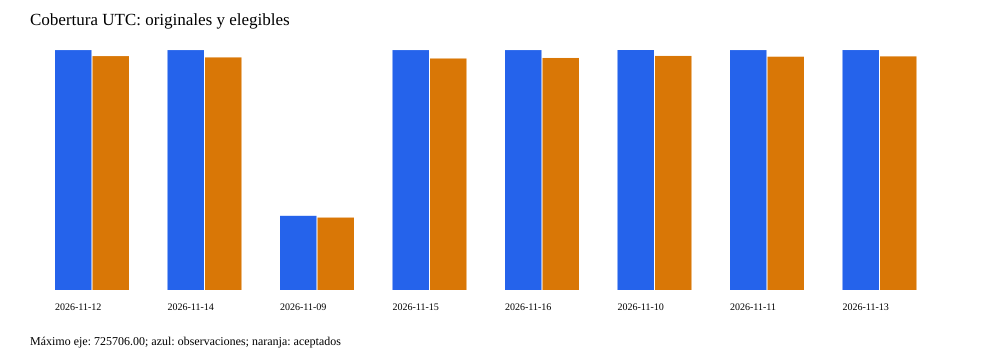

In [4]:
def tabla(rows, columns):
    if len(rows)>200:
        raise ValueError('Solo tablas agregadas pequeñas')
    def value(x):
        return f'{x:.8f}' if isinstance(x,float) else str(x)
    text='| '+' | '.join(columns)+' |\n| '+' | '.join(['---']*len(columns))+' |\n'
    text+='\n'.join('| '+' | '.join(value(r.get(c,'')) for c in columns)+' |' for r in rows)
    display(Markdown(text))
analysis=meta['analisis']
print('Fuentes separadas:',meta['fuentes'])
tabla(analysis['cobertura_fecha'],['fecha_captura_utc','archivos','observaciones','estaciones','aceptados','discrepancia_total','primera_utc','ultima_utc'])
print('Frecuencia real por archivo y reloj interno del feed:',analysis['cadencia'])
print('Huecos por estación:',analysis['huecos'])
print('Cobertura de estaciones:',analysis['cobertura_estaciones'])
tabla(analysis['estaciones_menor_cobertura'],['station_id','capturas','elegibles','primera_utc','ultima_utc'])
display(SVG(filename=str(SOURCE/'analisis/cobertura.svg')))


## Calidad y objetivos observacionales

El catálogo real identifica human y electric_assist. Se usan sus conteos explícitos en `vehicle_types_available`, sin restar eléctricas del total. La extensión `num_ebikes_available` y el total se conservan; su discrepancia es un indicador, no una corrección automática ni prueba de cuál conteo es físicamente correcto.

Se conservan observaciones iguales de instantes distintos. Los 450 s son un umbral de frescura/continuidad provisional, justificado en la investigación original y conservado en esta ampliación. Inactividad no equivale a registro inválido. No se rellenan ausencias con cero. Los rechazos permanecen con motivos por objetivo; motivos superpuestos no se suman como filas distintas.


Reconciliación: {'entrada': 5302934, 'aceptados': 5150956, 'excluidos': 151978, 'schema_verificado': True, 'multiconjunto_reconciliado': True} {'candidatos': 15908802, 'aceptados': 14748181, 'excluidos': 1160621}


| tipo_registro | aceptado_silver | count |
| --- | --- | --- |
| activo | True | 5150956 |
| activo | False | 178 |
| inactivo | False | 151800 |

Distribuciones de los conteos elegibles: {'convencionales': {'n': 5150956, 'min': 0, 'max': 85, 'media': 7.7406038801340955, 'p25_p50_p75_p95': [1, 5, 11, 26]}, 'electricas': {'n': 5150956, 'min': 0, 'max': 114, 'media': 6.302659739279465, 'p25_p50_p75_p95': [1, 3, 8, 25]}}
Observaciones con cero: {'convencionales': {'observaciones_cero': 839964, 'estaciones_con_cero': 1561}, 'electricas': {'observaciones_cero': 1002896, 'estaciones_con_cero': 2243}}
Episodios de cero, duración observada entre capturas: {'convencionales': {'episodios': 19033, 'max_s': 631192.9839999676, 'p50_p95_s': [2399.9249999523163, 49799.91200017929]}, 'electricas': {'episodios': 60904, 'max_s': 451499.7569999695, 'p50_p95_s': [1201.8759999275208, 20700.18800020218]}}


| fecha_nueva_york | dia_semana_iso | observaciones | convencionales_media | electricas_media |
| --- | --- | --- | --- | --- |
| 2026-11-09 | 1 | 375480 | 7.65219561 | 6.32847269 |
| 2026-11-10 | 2 | 725646 | 7.69075529 | 6.29434215 |
| 2026-11-11 | 3 | 725472 | 7.68590731 | 6.19799123 |
| 2026-11-12 | 4 | 725472 | 7.74301698 | 6.06589946 |
| 2026-11-14 | 6 | 725472 | 7.79087530 | 6.42163429 |
| 2026-11-16 | 1 | 574332 | 7.72579539 | 6.39977140 |
| 2026-11-13 | 5 | 725588 | 7.79891936 | 6.20266589 |
| 2026-11-15 | 7 | 725472 | 7.79247906 | 6.54672193 |

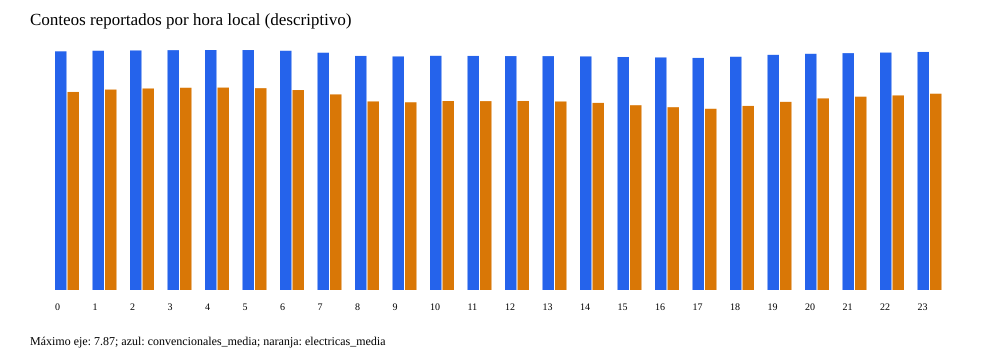

In [5]:
print('Reconciliación:',meta['conteos']['silver'],meta['conteos']['gold'])
tabla(analysis['exclusiones_silver'],['tipo_registro','aceptado_silver','count'])
print('Distribuciones de los conteos elegibles:',analysis['distribuciones'])
print('Observaciones con cero:',analysis['ceros'])
print('Episodios de cero, duración observada entre capturas:',{t:v['resumen'] for t,v in analysis['episodios_cero'].items()})
tabla(analysis['por_dia_local'],['fecha_nueva_york','dia_semana_iso','observaciones','convencionales_media','electricas_media'])
display(SVG(filename=str(SOURCE/'analisis/por_hora.svg')))


## RDD, evaluación diferida y particiones

El ejercicio RDD cuenta categorías de elegibilidad/discrepancia usando `map` y `reduceByKey`; reconcilia contra `groupBy` de DataFrame. Su salida tiene como máximo seis categorías, sin llevar el histórico al driver.

La demostración mide jobs de un grupo nuevo: construir `select/where/withColumn` y consultar el plan no inicia jobs; `count` sí. La proyección reduce columnas leídas y Catalyst empuja filtros cuando el origen lo admite. `PartitionFilters` demuestra descarte de particiones; no es lo mismo que filtrar filas después de leerlas.


In [6]:
print(json.dumps(meta['rdd_y_lazy'],indent=2))
print((SOURCE/'analisis/plan_lazy.txt').read_text())
print('Plan físico de Gold al filtrar una fecha UTC:')
print((SOURCE/'analisis/plan_gold_fecha.txt').read_text())
assert meta['rdd_y_lazy']['jobs_antes']==meta['rdd_y_lazy']['jobs_tras_plan']
assert meta['rdd_y_lazy']['jobs_tras_accion']
assert meta['rdd_y_lazy']['rdd_reconcilia_con_dataframe']


{
  "jobs_antes": [],
  "jobs_tras_plan": [],
  "jobs_tras_accion": [
    60,
    59
  ],
  "filas_aceptadas_accion": 5150956,
  "rdd_operaciones": [
    "map",
    "reduceByKey"
  ],
  "categorias_rdd": [
    {
      "aceptado_silver": "False",
      "discrepancia_total": "False",
      "n": 151831
    },
    {
      "aceptado_silver": "False",
      "discrepancia_total": "True",
      "n": 147
    },
    {
      "aceptado_silver": "True",
      "discrepancia_total": "False",
      "n": 4980757
    },
    {
      "aceptado_silver": "True",
      "discrepancia_total": "True",
      "n": 170199
    }
  ],
  "rdd_reconcilia_con_dataframe": true,
  "interpretacion": "select/where/withColumn crean un plan; count ejecuta. La proyecci\u00f3n permite leer menos columnas y el filtro se optimiza antes de la acci\u00f3n."
}
== Parsed Logical Plan ==
'Project [unresolvedstarwithcolumns(fecha_demo, 'to_date('captura_utc), None)]
+- Filter aceptado_silver#10355: boolean
   +- Project [station_id#10

## Gold y separación temporal

Se conserva el 9 parcial como contexto retrospectivo, sin usarlo como día de entrenamiento. Los cortes cronológicos y comunes a todas las estaciones se fijaron antes de entrenar: 10–13 train, 14 validación, 15–16 prueba, en días UTC completos. Los objetivos que alcanzan el siguiente periodo se purgan. Las ausencias reales de estaciones no se completan artificialmente.

Las 30 variables usan valores actuales, rezagos por tiempo a 5/10/15 minutos, cambios y estadísticas de 15 minutos estrictamente pasados; más calendario America/New_York. Se conserva UTC. Objetivos por timestamp con tolerancia ±30 s y horizonte efectivo; no se emparejan por posición ni se atraviesan huecos grandes. Calidad inicial y futura se aplican por separado; los indicadores futuros solo evalúan, nunca predicen. Imputación/transformaciones aprendidas se ajustan únicamente en train.


In [7]:
print('Cortes y parámetros:',meta['configuracion'])
print('Predictores explícitos:',meta['predictores'])
tabla(sorted(meta['conteos']['por_tipo_horizonte_particion'],key=lambda r:(r['tipo'],r['horizonte_min'],r['particion_temporal'])),['tipo','horizonte_min','particion_temporal','count'])
print('Gold está particionado por fecha UTC inicial y horizonte, no por estación.')


Cortes y parámetros: {'desde': '2026-11-09', 'hasta': '2026-11-16', 'inicio_modelado_utc': '2026-11-10 00:00:00', 'corte_validacion_utc': '2026-11-14 00:00:00', 'corte_prueba_utc': '2026-11-15 00:00:00', 'fin_exclusivo_utc': '2026-11-17 00:00:00', 'max_edad_s': 450, 'hueco_max_s': 450, 'tolerancia_s': 30, 'cores': 2, 'driver_memory': '4g', 'shuffle_partitions': 32}
Predictores explícitos: ['convencionales_actual', 'convencionales_lag5', 'convencionales_cambio5', 'convencionales_lag10', 'convencionales_cambio10', 'convencionales_lag15', 'convencionales_cambio15', 'convencionales_media15', 'convencionales_min15', 'convencionales_max15', 'convencionales_std15', 'convencionales_n15', 'electricas_actual', 'electricas_lag5', 'electricas_cambio5', 'electricas_lag10', 'electricas_cambio10', 'electricas_lag15', 'electricas_cambio15', 'electricas_media15', 'electricas_min15', 'electricas_max15', 'electricas_std15', 'electricas_n15', 'hora_local', 'minuto_local', 'dia_semana_iso', 'fin_semana', '

| tipo | horizonte_min | particion_temporal | count |
| --- | --- | --- | --- |
| convencionales | 5 | prueba | 1399056 |
| convencionales | 5 | train | 2824097 |
| convencionales | 5 | validacion | 700836 |
| convencionales | 10 | prueba | 1396457 |
| convencionales | 10 | train | 2821248 |
| convencionales | 10 | validacion | 698340 |
| convencionales | 15 | prueba | 1393862 |
| convencionales | 15 | train | 2818438 |
| convencionales | 15 | validacion | 695847 |
| electricas | 5 | prueba | 1399056 |
| electricas | 5 | train | 2824097 |
| electricas | 5 | validacion | 700836 |
| electricas | 10 | prueba | 1396457 |
| electricas | 10 | train | 2821248 |
| electricas | 10 | validacion | 698340 |
| electricas | 15 | prueba | 1393862 |
| electricas | 15 | train | 2818438 |
| electricas | 15 | validacion | 695847 |

Gold está particionado por fecha UTC inicial y horizonte, no por estación.


## Entrenamiento y comparación

Se comparan persistencia, LR sin regularización y ridge 0.01/0.1, RF de 8 árboles/profundidad 4 y RF de 16/profundidad 6. La tercera regularización prueba el extremo sin penalización, sin búsqueda exhaustiva. Los parámetros están fijados antes de consultar prueba.

Se selecciona por MAE de validación, con RMSE y R² adicionales y desempate determinista publicado. Las predicciones negativas se acotan a cero, sin redondear a enteros. Persistencia no requiere entrenamiento; si gana se conserva. Se guardan todos los candidatos MLlib y, aparte, ganador y mejor referencia MLlib. No se elige un horizonte usando prueba.


In [8]:
result=json.loads((SOURCE/'modelos/resultado.json').read_text())
frozen=json.loads((SOURCE/'modelos/seleccion_congelada.json').read_text())
tabla(frozen['comparativa_validacion'],['tipo','horizonte_min','candidato','n','MAE','RMSE','R2'])
print('Ajustes MLlib:',meta['ajustes_mllib'])
print('Selecciones congeladas:',meta['selecciones'])
print('Congelación:',frozen['congelada_utc'],'; inicio prueba:',result['lectura_prueba_utc'])
assert frozen['congelada_utc']<result['lectura_prueba_utc']


| tipo | horizonte_min | candidato | n | MAE | RMSE | R2 |
| --- | --- | --- | --- | --- | --- | --- |
| convencionales | 5 | persistencia | 700836 | 0.07232362 | 0.32078247 | 0.99877513 |
| convencionales | 5 | lr_ridge_001 | 700836 | 0.08597957 | 0.32809707 | 0.99871863 |
| convencionales | 5 | lr_ridge_01 | 700836 | 0.09346398 | 0.33062599 | 0.99869880 |
| convencionales | 5 | lr_sin_regularizar | 700836 | 0.08357812 | 0.32273052 | 0.99876021 |
| convencionales | 5 | rf_8_depth4 | 700836 | 1.86003418 | 2.78317161 | 0.90779606 |
| convencionales | 5 | rf_16_depth6 | 700836 | 0.67730368 | 1.95365461 | 0.95456766 |
| convencionales | 10 | persistencia | 698340 | 0.12950568 | 0.45484759 | 0.99753727 |
| convencionales | 10 | lr_ridge_001 | 698340 | 0.14959014 | 0.46029799 | 0.99747789 |
| convencionales | 10 | lr_ridge_01 | 698340 | 0.15629531 | 0.46213708 | 0.99745770 |
| convencionales | 10 | lr_sin_regularizar | 698340 | 0.14756674 | 0.45626833 | 0.99752186 |
| convencionales | 10 | rf_8_depth4 | 698340 | 1.75112189 | 2.69145523 | 0.91376973 |
| convencionales | 10 | rf_16_depth6 | 698340 | 0.70023149 | 1.98374625 | 0.95315560 |
| convencionales | 15 | persistencia | 695847 | 0.17823315 | 0.55864001 | 0.99628493 |
| convencionales | 15 | lr_ridge_001 | 695847 | 0.20415666 | 0.56329372 | 0.99622278 |
| convencionales | 15 | lr_ridge_01 | 695847 | 0.21040726 | 0.56479158 | 0.99620267 |
| convencionales | 15 | lr_sin_regularizar | 695847 | 0.20317521 | 0.56009853 | 0.99626551 |
| convencionales | 15 | rf_8_depth4 | 695847 | 1.78701906 | 2.71471722 | 0.91226929 |
| convencionales | 15 | rf_16_depth6 | 695847 | 0.72909113 | 2.02485719 | 0.95119197 |
| electricas | 5 | persistencia | 700836 | 0.18218100 | 0.55489457 | 0.99646725 |
| electricas | 5 | lr_ridge_001 | 700836 | 0.20514537 | 0.56123103 | 0.99638611 |
| electricas | 5 | lr_ridge_01 | 700836 | 0.21228035 | 0.56483221 | 0.99633958 |
| electricas | 5 | lr_sin_regularizar | 700836 | 0.20197637 | 0.55628701 | 0.99644950 |
| electricas | 5 | rf_8_depth4 | 700836 | 1.36496623 | 2.82529240 | 0.90841616 |
| electricas | 5 | rf_16_depth6 | 700836 | 0.83545137 | 2.37539705 | 0.93526122 |
| electricas | 10 | persistencia | 698340 | 0.30460234 | 0.77843055 | 0.99304813 |
| electricas | 10 | lr_ridge_001 | 698340 | 0.33896536 | 0.78475264 | 0.99293475 |
| electricas | 10 | lr_ridge_01 | 698340 | 0.34439118 | 0.78723664 | 0.99288995 |
| electricas | 10 | lr_sin_regularizar | 698340 | 0.33657648 | 0.78132213 | 0.99299639 |
| electricas | 10 | rf_8_depth4 | 698340 | 1.38651957 | 2.86256867 | 0.90599009 |
| electricas | 10 | rf_16_depth6 | 698340 | 0.89671129 | 2.41854354 | 0.93289272 |
| electricas | 15 | persistencia | 695847 | 0.40273221 | 0.94891027 | 0.98967035 |
| electricas | 15 | lr_ridge_001 | 695847 | 0.44751221 | 0.95658424 | 0.98950260 |
| electricas | 15 | lr_ridge_01 | 695847 | 0.45209269 | 0.95862163 | 0.98945784 |
| electricas | 15 | lr_sin_regularizar | 695847 | 0.44736340 | 0.95382153 | 0.98956315 |
| electricas | 15 | rf_8_depth4 | 695847 | 1.34671947 | 2.81981756 | 0.90878271 |
| electricas | 15 | rf_16_depth6 | 695847 | 0.99882926 | 2.49005969 | 0.92886970 |

Ajustes MLlib: 30
Selecciones congeladas: [{'tipo': 'convencionales', 'horizonte_min': 5, 'candidato': 'persistencia', 'requiere_entrenamiento': False}, {'tipo': 'convencionales', 'horizonte_min': 10, 'candidato': 'persistencia', 'requiere_entrenamiento': False}, {'tipo': 'convencionales', 'horizonte_min': 15, 'candidato': 'persistencia', 'requiere_entrenamiento': False}, {'tipo': 'electricas', 'horizonte_min': 5, 'candidato': 'persistencia', 'requiere_entrenamiento': False}, {'tipo': 'electricas', 'horizonte_min': 10, 'candidato': 'persistencia', 'requiere_entrenamiento': False}, {'tipo': 'electricas', 'horizonte_min': 15, 'candidato': 'persistencia', 'requiere_entrenamiento': False}]
Congelación: 2026-11-17T18:32:41.532703+00:00 ; inicio prueba: 2026-11-17T18:32:41.672055+00:00


In [9]:
tabla(result['metricas_prueba'],['tipo','horizonte_min','candidato','seleccionado','n','MAE','RMSE','R2'])
winners={(r['tipo'],r['horizonte_min']):r['candidato'] for r in meta['metricas']}
subgroups=[{**r,'categoria':r[r['dimension']]} for r in result['subgrupos_prueba'] if r['candidato']==winners[r['tipo'],r['horizonte_min']]]
tabla(subgroups,['tipo','horizonte_min','candidato','dimension','categoria','n','MAE','RMSE','R2'])
tabla(result['resumen_estaciones'],['tipo','horizonte_min','candidato','estaciones','MAE_macro','p50_p95_MAE_estacion'])


| tipo | horizonte_min | candidato | seleccionado | n | MAE | RMSE | R2 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| convencionales | 5 | persistencia | True | 1399056 | 0.07996535 | 0.34623192 | 0.99862410 |
| convencionales | 5 | lr_ridge_001 | False | 1399056 | 0.09404152 | 0.35965353 | 0.99851536 |
| convencionales | 5 | lr_ridge_01 | False | 1399056 | 0.10162284 | 0.36410551 | 0.99847838 |
| convencionales | 5 | lr_sin_regularizar | False | 1399056 | 0.09135302 | 0.34942161 | 0.99859863 |
| convencionales | 5 | rf_8_depth4 | False | 1399056 | 1.86563754 | 2.78079979 | 0.91124507 |
| convencionales | 5 | rf_16_depth6 | False | 1399056 | 0.70384808 | 1.96800164 | 0.95554670 |
| convencionales | 10 | persistencia | True | 1396457 | 0.14172653 | 0.48616459 | 0.99728707 |
| convencionales | 10 | lr_ridge_001 | False | 1396457 | 0.16176961 | 0.49489796 | 0.99718873 |
| convencionales | 10 | lr_ridge_01 | False | 1396457 | 0.16856021 | 0.49814152 | 0.99715176 |
| convencionales | 10 | lr_sin_regularizar | False | 1396457 | 0.15948193 | 0.48726807 | 0.99727475 |
| convencionales | 10 | rf_8_depth4 | False | 1396457 | 1.75997771 | 2.68324549 | 0.91735967 |
| convencionales | 10 | rf_16_depth6 | False | 1396457 | 0.72648364 | 1.99658651 | 0.95424406 |
| convencionales | 15 | persistencia | True | 1393862 | 0.19407588 | 0.59803741 | 0.99589468 |
| convencionales | 15 | lr_ridge_001 | False | 1393862 | 0.21952430 | 0.60418611 | 0.99580982 |
| convencionales | 15 | lr_ridge_01 | False | 1393862 | 0.22586714 | 0.60682230 | 0.99577318 |
| convencionales | 15 | lr_sin_regularizar | False | 1393862 | 0.21822935 | 0.59790984 | 0.99589643 |
| convencionales | 15 | rf_8_depth4 | False | 1393862 | 1.79551284 | 2.70918376 | 0.91575043 |
| convencionales | 15 | rf_16_depth6 | False | 1393862 | 0.75890904 | 2.04016207 | 0.95222287 |
| electricas | 5 | persistencia | True | 1399056 | 0.18320925 | 0.56764940 | 0.99691279 |
| electricas | 5 | lr_ridge_001 | False | 1399056 | 0.20658291 | 0.57914479 | 0.99678648 |
| electricas | 5 | lr_ridge_01 | False | 1399056 | 0.21396937 | 0.58594800 | 0.99671054 |
| electricas | 5 | lr_sin_regularizar | False | 1399056 | 0.20314794 | 0.56844664 | 0.99690411 |
| electricas | 5 | rf_8_depth4 | False | 1399056 | 1.46765505 | 3.31316146 | 0.89483007 |
| electricas | 5 | rf_16_depth6 | False | 1399056 | 0.90220375 | 2.78618353 | 0.92562520 |
| electricas | 10 | persistencia | True | 1396457 | 0.30528616 | 0.80221349 | 0.99383345 |
| electricas | 10 | lr_ridge_001 | False | 1396457 | 0.33995423 | 0.80945327 | 0.99372165 |
| electricas | 10 | lr_ridge_01 | False | 1396457 | 0.34566287 | 0.81408633 | 0.99364957 |
| electricas | 10 | lr_sin_regularizar | False | 1396457 | 0.33734884 | 0.80182847 | 0.99383937 |
| electricas | 10 | rf_8_depth4 | False | 1396457 | 1.49359832 | 3.34911030 | 0.89252166 |
| electricas | 10 | rf_16_depth6 | False | 1396457 | 0.96688343 | 2.83661027 | 0.92289875 |
| electricas | 15 | persistencia | True | 1393862 | 0.40343664 | 0.98678549 | 0.99066837 |
| electricas | 15 | lr_ridge_001 | False | 1393862 | 0.44819620 | 0.99141544 | 0.99058059 |
| electricas | 15 | lr_ridge_01 | False | 1393862 | 0.45303164 | 0.99498916 | 0.99051256 |
| electricas | 15 | lr_sin_regularizar | False | 1393862 | 0.44765294 | 0.98557126 | 0.99069132 |
| electricas | 15 | rf_8_depth4 | False | 1393862 | 1.44453631 | 3.29727354 | 0.89581093 |
| electricas | 15 | rf_16_depth6 | False | 1393862 | 1.06905818 | 2.89105792 | 0.91990124 |

| tipo | horizonte_min | candidato | dimension | categoria | n | MAE | RMSE | R2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| convencionales | 5 | persistencia | estrato_discrepancia | con_discrepancias | 82676 | 0.39486671 | 0.88653001 | 0.99416546 |
| convencionales | 5 | persistencia | estrato_discrepancia | sin_discrepancias | 1316380 | 0.06018779 | 0.27936416 | 0.99906554 |
| convencionales | 5 | persistencia | cambio_objetivo | cambia | 96266 | 1.16215486 | 1.31992178 | 0.98694065 |
| convencionales | 5 | persistencia | cambio_objetivo | igual | 1302790 | 0.00000000 | 0.00000000 | 1.00000000 |
| convencionales | 10 | persistencia | estrato_discrepancia | con_discrepancias | 82618 | 0.57264761 | 1.12350131 | 0.99063929 |
| convencionales | 10 | persistencia | estrato_discrepancia | sin_discrepancias | 1313839 | 0.11462896 | 0.41454131 | 0.99794209 |
| convencionales | 10 | persistencia | cambio_objetivo | cambia | 158224 | 1.25085322 | 1.44431169 | 0.98409690 |
| convencionales | 10 | persistencia | cambio_objetivo | igual | 1238233 | 0.00000000 | 0.00000000 | 1.00000000 |
| convencionales | 15 | persistencia | estrato_discrepancia | con_discrepancias | 82554 | 0.71958960 | 1.32971412 | 0.98684747 |
| convencionales | 15 | persistencia | estrato_discrepancia | sin_discrepancias | 1311308 | 0.16099193 | 0.51850809 | 0.99678109 |
| convencionales | 15 | persistencia | cambio_objetivo | cambia | 204211 | 1.32468378 | 1.56242320 | 0.98107938 |
| convencionales | 15 | persistencia | cambio_objetivo | igual | 1189651 | 0.00000000 | 0.00000000 | 1.00000000 |
| electricas | 5 | persistencia | estrato_discrepancia | con_discrepancias | 82676 | 0.84268712 | 1.39818036 | 0.99239290 |
| electricas | 5 | persistencia | estrato_discrepancia | sin_discrepancias | 1316380 | 0.14179036 | 0.46870490 | 0.99761708 |
| electricas | 5 | persistencia | cambio_objetivo | cambia | 200421 | 1.27890790 | 1.49977504 | 0.98926322 |
| electricas | 5 | persistencia | cambio_objetivo | igual | 1198635 | 0.00000000 | 0.00000000 | 1.00000000 |
| electricas | 10 | persistencia | estrato_discrepancia | con_discrepancias | 82618 | 1.13406280 | 1.83877769 | 0.98682264 |
| electricas | 10 | persistencia | estrato_discrepancia | sin_discrepancias | 1313839 | 0.25317029 | 0.68658647 | 0.99488731 |
| electricas | 10 | persistencia | cambio_objetivo | cambia | 301748 | 1.41283124 | 1.72576456 | 0.98440668 |
| electricas | 10 | persistencia | cambio_objetivo | igual | 1094709 | 0.00000000 | 0.00000000 | 1.00000000 |
| electricas | 15 | persistencia | estrato_discrepancia | con_discrepancias | 82554 | 1.36974586 | 2.20704921 | 0.98109014 |
| electricas | 15 | persistencia | estrato_discrepancia | sin_discrepancias | 1311308 | 0.34260220 | 0.85345650 | 0.99209101 |
| electricas | 15 | persistencia | cambio_objetivo | cambia | 370905 | 1.51611599 | 1.91293979 | 0.97966687 |
| electricas | 15 | persistencia | cambio_objetivo | igual | 1022957 | 0.00000000 | 0.00000000 | 1.00000000 |

| tipo | horizonte_min | candidato | estaciones | MAE_macro | p50_p95_MAE_estacion |
| --- | --- | --- | --- | --- | --- |
| convencionales | 5 | persistencia | 2459 | 0.07973816 | [0.04, 0.27304347826086955] |
| convencionales | 10 | persistencia | 2459 | 0.14133799 | [0.078397212543554, 0.46689895470383275] |
| convencionales | 15 | persistencia | 2459 | 0.19354089 | [0.11169284467713787, 0.6212914485165794] |
| electricas | 5 | persistencia | 2459 | 0.18287304 | [0.10434782608695652, 0.5895652173913043] |
| electricas | 10 | persistencia | 2459 | 0.30472688 | [0.1916376306620209, 0.921602787456446] |
| electricas | 15 | persistencia | 2459 | 0.40283736 | [0.2670157068062827, 1.1832460732984293] |

## Importancia de variables de Random Forest

Se conserva `featureImportances` de ambos RF por tipo/horizonte, calculada por los modelos ajustados con train. La tabla siguiente muestra sus cinco componentes principales, incluyendo indicadores de ausencia cuando corresponda. No son efectos causales: variables actuales y rezagos están correlacionados y la imputación puede afectar la atribución. La importancia de una variable no acredita exactitud física de la fuente.


In [10]:
importance=[]
for path in sorted((SOURCE/'modelos/interpretacion').glob('*/*.json')):
    item=json.loads(path.read_text())
    for row in sorted(item['importancias'],key=lambda r:-r['importancia'])[:5]:
        importance.append({'tipo':item['tipo'],'horizonte_min':item['horizonte_min'],'candidato':item['candidato'],**row})
assert len(list((SOURCE/'modelos/interpretacion').glob('*/*.json')))==12
assert len(importance)==60
tabla(importance,['tipo','horizonte_min','candidato','variable_vector','importancia'])


| tipo | horizonte_min | candidato | variable_vector | importancia |
| --- | --- | --- | --- | --- |
| convencionales | 10 | rf_16_depth6 | convencionales_max15__mediana | 0.22828820 |
| convencionales | 10 | rf_16_depth6 | convencionales_actual__mediana | 0.21665322 |
| convencionales | 10 | rf_16_depth6 | convencionales_lag5__mediana | 0.16892506 |
| convencionales | 10 | rf_16_depth6 | convencionales_lag15__mediana | 0.10694562 |
| convencionales | 10 | rf_16_depth6 | convencionales_media15__mediana | 0.09048973 |
| convencionales | 10 | rf_8_depth4 | convencionales_max15__mediana | 0.31624504 |
| convencionales | 10 | rf_8_depth4 | convencionales_actual__mediana | 0.24534220 |
| convencionales | 10 | rf_8_depth4 | convencionales_lag5__mediana | 0.20508626 |
| convencionales | 10 | rf_8_depth4 | convencionales_lag15__mediana | 0.12823266 |
| convencionales | 10 | rf_8_depth4 | convencionales_media15__mediana | 0.03980897 |
| convencionales | 15 | rf_16_depth6 | convencionales_max15__mediana | 0.23468410 |
| convencionales | 15 | rf_16_depth6 | convencionales_actual__mediana | 0.21032964 |
| convencionales | 15 | rf_16_depth6 | convencionales_lag5__mediana | 0.16578015 |
| convencionales | 15 | rf_16_depth6 | convencionales_lag15__mediana | 0.10709218 |
| convencionales | 15 | rf_16_depth6 | convencionales_media15__mediana | 0.09487846 |
| convencionales | 15 | rf_8_depth4 | convencionales_max15__mediana | 0.31575489 |
| convencionales | 15 | rf_8_depth4 | convencionales_actual__mediana | 0.24320562 |
| convencionales | 15 | rf_8_depth4 | convencionales_lag5__mediana | 0.20607929 |
| convencionales | 15 | rf_8_depth4 | convencionales_lag15__mediana | 0.12841519 |
| convencionales | 15 | rf_8_depth4 | convencionales_min15__mediana | 0.03752762 |
| convencionales | 5 | rf_16_depth6 | convencionales_max15__mediana | 0.23842646 |
| convencionales | 5 | rf_16_depth6 | convencionales_actual__mediana | 0.21557490 |
| convencionales | 5 | rf_16_depth6 | convencionales_lag5__mediana | 0.17095358 |
| convencionales | 5 | rf_16_depth6 | convencionales_lag15__mediana | 0.10521398 |
| convencionales | 5 | rf_16_depth6 | convencionales_min15__mediana | 0.09359884 |
| convencionales | 5 | rf_8_depth4 | convencionales_max15__mediana | 0.31627981 |
| convencionales | 5 | rf_8_depth4 | convencionales_actual__mediana | 0.24202884 |
| convencionales | 5 | rf_8_depth4 | convencionales_lag5__mediana | 0.19998047 |
| convencionales | 5 | rf_8_depth4 | convencionales_lag15__mediana | 0.12829261 |
| convencionales | 5 | rf_8_depth4 | convencionales_min15__mediana | 0.03780037 |
| electricas | 10 | rf_16_depth6 | electricas_actual__mediana | 0.28849704 |
| electricas | 10 | rf_16_depth6 | electricas_lag5__mediana | 0.16688585 |
| electricas | 10 | rf_16_depth6 | electricas_media15__mediana | 0.12748536 |
| electricas | 10 | rf_16_depth6 | electricas_min15__mediana | 0.12102779 |
| electricas | 10 | rf_16_depth6 | electricas_max15__mediana | 0.11732435 |
| electricas | 10 | rf_8_depth4 | electricas_actual__mediana | 0.38978287 |
| electricas | 10 | rf_8_depth4 | electricas_max15__mediana | 0.12792098 |
| electricas | 10 | rf_8_depth4 | electricas_lag15__mediana | 0.12253965 |
| electricas | 10 | rf_8_depth4 | electricas_media15__mediana | 0.12019553 |
| electricas | 10 | rf_8_depth4 | electricas_lag5__mediana | 0.11778406 |
| electricas | 15 | rf_16_depth6 | electricas_actual__mediana | 0.28716778 |
| electricas | 15 | rf_16_depth6 | electricas_lag5__mediana | 0.16682938 |
| electricas | 15 | rf_16_depth6 | electricas_media15__mediana | 0.14277534 |
| electricas | 15 | rf_16_depth6 | electricas_min15__mediana | 0.11789214 |
| electricas | 15 | rf_16_depth6 | electricas_max15__mediana | 0.11509609 |
| electricas | 15 | rf_8_depth4 | electricas_actual__mediana | 0.38093063 |
| electricas | 15 | rf_8_depth4 | electricas_media15__mediana | 0.18091638 |
| electricas | 15 | rf_8_depth4 | electricas_lag15__mediana | 0.12226473 |
| electricas | 15 | rf_8_depth4 | electricas_max15__mediana | 0.12210411 |
| electricas | 15 | rf_8_depth4 | electricas_lag5__mediana | 0.08824378 |
| electricas | 5 | rf_16_depth6 | electricas_actual__mediana | 0.29080197 |
| electricas | 5 | rf_16_depth6 | electricas_lag5__mediana | 0.16177928 |
| electricas | 5 | rf_16_depth6 | electricas_media15__mediana | 0.13447851 |
| electricas | 5 | rf_16_depth6 | electricas_min15__mediana | 0.12273158 |
| electricas | 5 | rf_16_depth6 | electricas_max15__mediana | 0.11997832 |
| electricas | 5 | rf_8_depth4 | electricas_actual__mediana | 0.38786570 |
| electricas | 5 | rf_8_depth4 | electricas_max15__mediana | 0.12726007 |
| electricas | 5 | rf_8_depth4 | electricas_lag15__mediana | 0.12595631 |
| electricas | 5 | rf_8_depth4 | electricas_media15__mediana | 0.12010630 |
| electricas | 5 | rf_8_depth4 | electricas_lag5__mediana | 0.11755100 |

Recarga de ganadores: [{'tipo': 'convencionales', 'horizonte_min': 5, 'n': 1399056, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.07996534806326551}, {'tipo': 'convencionales', 'horizonte_min': 10, 'n': 1396457, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.14172652648810524}, {'tipo': 'convencionales', 'horizonte_min': 15, 'n': 1393862, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.19407588412626214}, {'tipo': 'electricas', 'horizonte_min': 5, 'n': 1399056, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.18320924966548874}, {'tipo': 'electricas', 'horizonte_min': 10, 'n': 1396457, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.3052861634837306}, {'tipo': 'electricas', 'horizonte_min': 15, 'n': 1393862, 'nulos': 0, 'max_diferencia': 0.0, 'MAE_reproducido': 0.4034366386342407}]
Recarga de referencias MLlib: [{'tipo': 'convencionales', 'horizonte_min': 5, 'candidato': 'lr_sin_regularizar', 'n': 1399056, 'nulos': 0, 'max_diferencia': 0.0}, {'

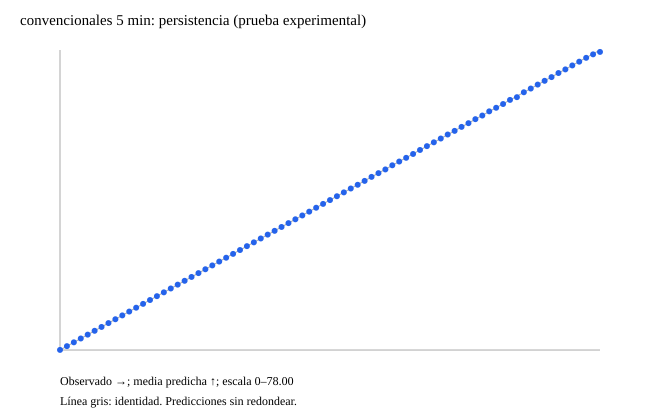

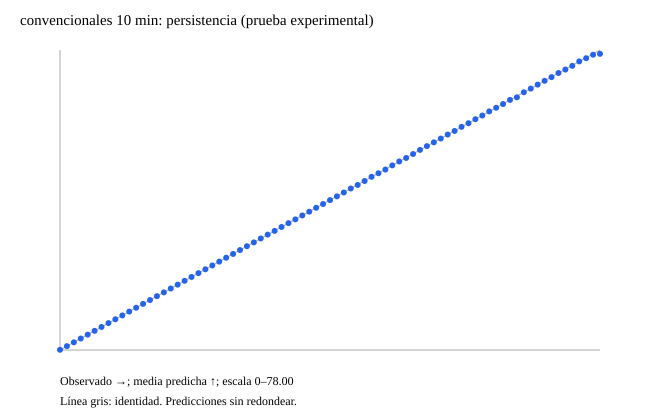

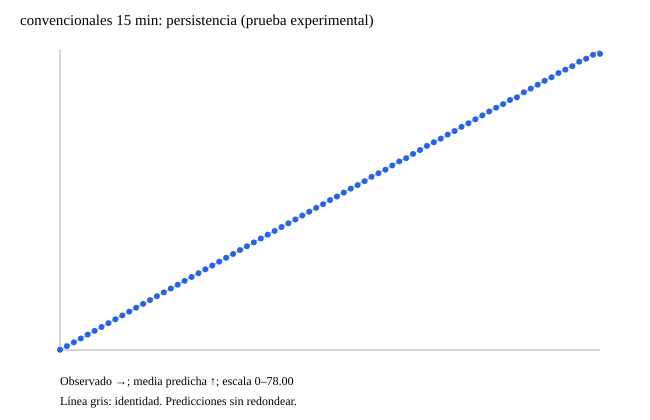

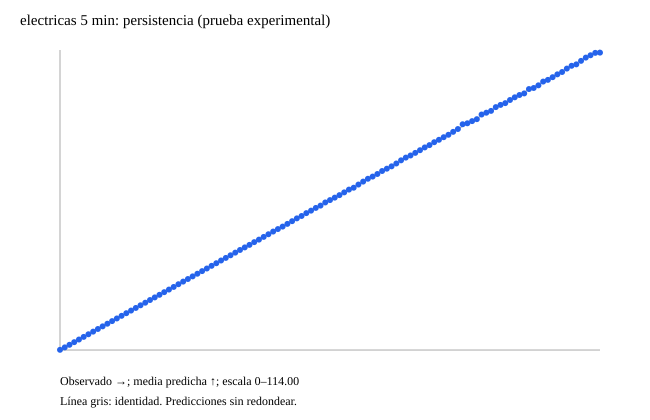

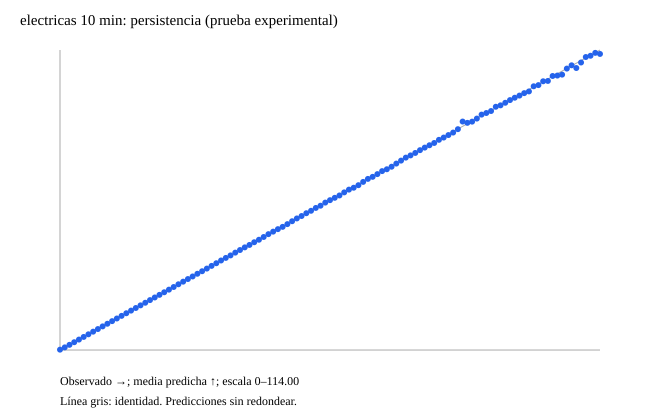

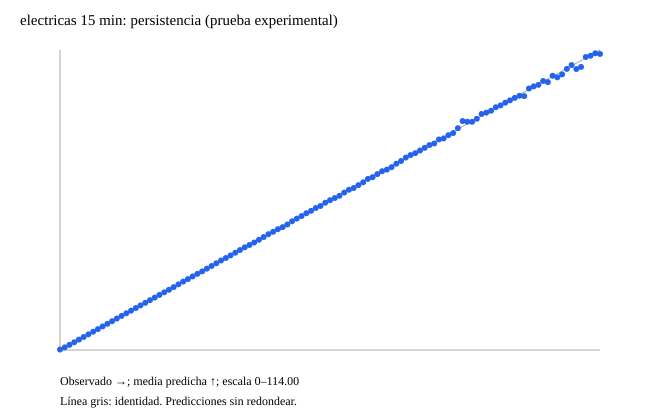

Artefactos y modelos conservados: /opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T171917344468Z
Manifest de esta ejecución: /opt/UNIDAD1/Dim-Disponibilidad/data/ejecuciones/20261117T171917344468Z/manifiesto.json


In [11]:
print('Recarga de ganadores:',meta['recarga_verificada'])
print('Recarga de referencias MLlib:',meta['recarga_referencias_mllib'])
assert len(meta['recarga_verificada'])==len(meta['recarga_referencias_mllib'])==6
assert all(r['max_diferencia']<=1e-10 and r['nulos']==0 for r in meta['recarga_verificada']+meta['recarga_referencias_mllib'])
comprobar_artefactos(SOURCE,meta['artefactos'])
for key in winners:
    tipo,h=key
    display(SVG(filename=str(SOURCE/'modelos'/f'{tipo}_{h}min_observado.svg')))
print('Artefactos y modelos conservados:',SOURCE)
print('Manifest de esta ejecución:',RUN/'manifiesto.json')


## Conclusiones y límites de la evidencia

Las métricas anteriores permiten comparar estos candidatos sobre los días reservados; no se presupone que persistencia gane ni se cambia la selección después de prueba. El error condicionado a cambios evita confundir estabilidad del inventario con capacidad de anticipar movimientos. Las comparaciones con/sin discrepancias se mantienen y no identifican cuál representación refleja mejor la realidad física.

Son siete días UTC completos y un tramo de contexto: no demuestran estacionalidad ni un patrón semanal repetible. Hay muy pocos días independientes, train no incluye fin de semana y la validación es sábado UTC (viernes por la noche y sábado locales); ese cambio de régimen limita las conclusiones. Las decisiones operativas requerirán más fechas y un umbral de error acordado. La prueba preliminar de un día fue inspeccionada y queda separada; no se usa como evaluación final.

**Hallazgo técnico:** contar flags de exclusión solapados como filas descartadas duplica casos; se reconcilian aceptados/excluidos y se conservan razones por objetivo. Un conteo igual entre capturas sigue siendo una observación temporal válida.

**Reflexión técnica:** evaluación diferida permite optimizar el plan antes del trabajo; validar tipos y calidad antes de Gold evita propagar errores a consumidores. Ninguna métrica sola describe el coste operativo: MAE mide error medio, RMSE enfatiza errores grandes, R² depende también de la variación entre estaciones. El estudiante debe poder explicar estas decisiones con sus propias palabras.

Faltan las evidencias personales: capturas con reloj/perfil, publicación e historial real del aporte, pitch y sustentación individual. U2 no está implementada. No se realizan commits ni push.
